# 5. Abundance and bias of haloes

This notebook follows Secs. 3.2 and 3.3 of Paper I.
It assembles the mass function from a multiplicity function, compares the sixteen fits the package provides, differentiates the default `tinker08` with respect to the ten parameters, and checks the peak-background split of the bias fits (Table 4).
It ends on the figure of the abundance.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

import ggah_mod.halos as H
from ggah_mod import DIFFERENTIABLE
from ggah_mod.cosmology import PLANCK18, make_pk
from ggah_mod.halos.field import make_field

pk = make_pk("emu_pk")
c = PLANCK18
M = np.logspace(10.0, 16.0, 80 if FAST else 160)     # h^-1 Msun
K = np.logspace(-4.0, 2.0, 512)                      # h Mpc^-1
mj, kj = jnp.asarray(M), jnp.asarray(K)
near = lambda arr, value: int(np.argmin(np.abs(np.asarray(arr) - value)))

#: The four model choices of Sec. 3: the defaults of the DIFFERENTIABLE backend.
CHOICE = dict(mdef="200m", hmf_model="tinker08", bias_model="tinker10", cm_model="bhattacharya13")


def field(cosmo, **kw):
    """The halo field of Eq. (36) at ``cosmo`` on this notebook's grids."""
    return make_field(cosmo, DIFFERENTIABLE, pk, z=0.0, m=M, k=K, **{**CHOICE, **kw})


def dln(read):
    """``{param: d ln read(field) / d theta}`` by forward autodiff of the whole field."""
    out = {}
    for p in T.DPARAMS:
        v0 = float(getattr(c, p))
        scale = v0 if p in T.DLOG else 1.0
        out[p] = np.asarray(jax.jacfwd(lambda v, p=p: jnp.log(read(field(c.replace(**{p: v})))))(v0)) * scale
    return out


#: The directions the left-hand panels move, either side of the fiducial.
VARIANTS = (("Omega_m", 0.28), ("Omega_m", 0.34), ("h", 0.65), ("h", 0.70),
            ("Omega_k", -0.05), ("Omega_k", 0.05))


def variant_lines(axis, of, x):
    for p, v in VARIANTS:
        ls = (0, (5, 1.6)) if v < float(getattr(c, p)) else (0, (1, 1.4))
        axis.plot(x, of(c.replace(**{p: v})), color=T.DSTYLE[p][0], ls=ls, lw=1.1,
                  label=T.TEX[p][:-1] + rf" = {v:g}$")


def gradient_panel(axis, x, g, xlabel, ylabel, title, lin=1e-2):
    axis.grid(False)
    axis.axhspan(-lin, lin, color="0.90", zorder=0)
    for p in T.DPARAMS:
        if not np.all(g[p] == 0.0):
            colour, ls = T.DSTYLE[p]
            axis.plot(x, g[p], color=colour, ls=ls, lw=1.3, label=T.TEX[p])
    axis.axhline(0.0, color="k", lw=0.8)
    axis.set_xscale("log")
    axis.set_yscale("symlog", linthresh=lin)
    axis.set(xlabel=xlabel, ylabel=ylabel, title=title)
    axis.set_xlim(float(np.min(x)), float(np.max(x)))


def mass_axis_on_sigma(axis, sigma, masses=(1e10, 1e12, 1e13, 1e14, 1e15, 1e16)):
    """Masses along the top of a panel drawn against sigma, at the fiducial."""
    import matplotlib.ticker as mticker
    top = axis.twiny()
    top.grid(False)
    top.set_xscale("log")
    top.set_xlim(axis.get_xlim())
    top.set_xticks([float(np.exp(np.interp(np.log(mm), np.log(M), np.log(sigma)))) for mm in masses])
    top.set_xticklabels([rf"$10^{{{int(np.log10(mm))}}}$" for mm in masses])
    top.xaxis.set_minor_formatter(mticker.NullFormatter())
    top.set_xlabel(r"$M\ [h^{-1}M_\odot]$ at the fiducial")
    axis.set_xticks([t for t in (0.3, 0.5, 1.0, 2.0, 3.0) if sigma.min() <= t <= sigma.max()])
    axis.xaxis.set_major_formatter(mticker.FormatStrFormatter("%g"))
    axis.xaxis.set_minor_formatter(mticker.NullFormatter())


def bottom_legend(fig, axis):
    handles, labels = axis.get_legend_handles_labels()
    fig.legend(handles, labels, fontsize=6.6, ncol=10, loc="lower center", bbox_to_anchor=(0.5, -0.015),
               frameon=False, handlelength=1.5, columnspacing=1.0, handletextpad=0.4)
    fig.tight_layout(rect=(0, 0.055, 1, 1))


fid = field(c)
sigma = np.asarray(fid.sigma)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = True


## The mass function

The mass function is a multiplicity function $f(\sigma)$ times the Jacobian from $\sigma$ to mass (Eq. 31):

$$\frac{{\rm d}n}{{\rm d}M} = f(\sigma)\,\frac{\bar\rho_{\rm cb}}{M^2}\left|\frac{{\rm d}\ln\sigma}{{\rm d}\ln M}\right|.$$

The default, `tinker08`, is (Eq. 32)

$$f(\sigma) = A\left[\left(\frac{\sigma}{b}\right)^{-a} + 1\right]e^{-c/\sigma^2},$$

with parameters interpolated in $\log\Delta$ between the nine overdensities Tinker et al. tabulated.
The halo field holds the result; we rebuild it by hand from its own $\sigma$ and slope.

max |by hand / field - 1| = 2.2e-16


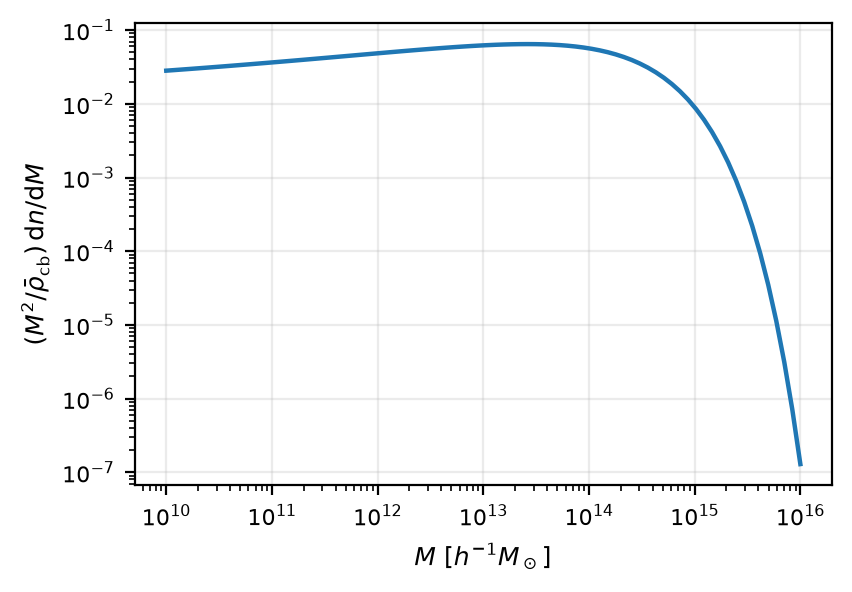

In [2]:
by_hand = H.make_multiplicity("tinker08")(fid.sigma, 0.0) * c.rho_cold / M**2 * jnp.abs(fid.dlns)
print(f"max |by hand / field - 1| = {float(jnp.max(jnp.abs(by_hand / fid.dndm - 1))):.1e}")

fig, ax = plt.subplots(figsize=(4.5, 3.0))
ax.loglog(M, M**2 / c.rho_cold * np.asarray(fid.dndm))
ax.set(xlabel=r"$M\ [h^{-1}M_\odot]$", ylabel=r"$(M^2/\bar\rho_{\rm cb})\,{\rm d}n/{\rm d}M$");

## Sixteen fits

The package re-implements sixteen multiplicity functions in JAX, following `colossus`.
`CALIBRATION` records, for each, the simulation suite, the halo finder, the overdensity and the redshift range it was fitted on.
At fixed $\sigma$ they disagree by tens of per cent, which is the size of the systematic a choice of fit carries.

In [3]:
import inspect

lo, hi = near(M, 1e12), near(M, 1e15)
vals = {}
for name, fn in H.MULTIPLICITY.items():
    if name.startswith("tinker08_csst"):
        continue                                   # optional emulator, needs emu_hmf
    kw = {"cosmo": c} if "cosmo" in inspect.signature(fn).parameters else {}
    vals[name] = np.asarray(fn(fid.sigma, 0.0, **kw))
print(f"{len(vals)} fits;  f(sigma) at 1e12 and 1e15:")
for name, v in vals.items():
    print(f"  {name:18s} {v[lo]:.4f}  {v[hi]:.5f}")
v12 = np.array([v[lo] for v in vals.values()])
v15 = np.array([v[hi] for v in vals.values()])
print(f"spread: {np.ptp(v12) / np.median(v12):.0%} of the median at 1e12, {np.ptp(v15) / np.median(v15):.0%} at 1e15")

16 fits;  f(sigma) at 1e12 and 1e15:
  press74            0.4596  0.01712
  sheth99            0.3113  0.03116
  jenkins01          0.3147  0.03313
  warren06           0.3023  0.03257
  tinker08           0.3304  0.03154
  crocce10           0.3013  0.04061
  bhattacharya11     0.3039  0.03937
  watson13           0.3036  0.03672
  angulo12           0.3032  0.03637
  bocquet16          0.3106  0.03199
  despali16          0.3140  0.02537
  rodriguezpuebla16  0.2948  0.02635
  comparat17         0.2993  0.02102
  seppi20            0.2540  0.02146
  yung24             0.4749  0.04233
  yung25             0.3872  0.03923
spread: 72% of the median at 1e12, 78% at 1e15


## Derivatives

A multiplicity function is a function of $\sigma$ alone, so at fixed $\sigma$ it has no cosmological derivative.
What the cosmology moves is $\sigma(M)$, so we differentiate at fixed mass, through the whole field.

In [4]:
fit = H.make_multiplicity("tinker08")
g = dln(lambda f: fit(f.sigma, 0.0))
print(f"{'':10s}{'1e12':>10s}{'1e15':>10s}")
for p in T.DPARAMS:
    print(f"{p:10s}{g[p][lo]:+10.4g}{g[p][hi]:+10.4g}")

                1e12      1e15
Omega_m      -0.3858    +6.095
Omega_b      +0.1153    -1.842
h            -0.4417     +7.18
sum_mnu     +0.00492  -0.09671
T_cmb      +0.005212  -0.08233
n_s           -0.334    +1.089
ln10A_s      -0.1586    +3.511
w0          +0.07859     -1.74
wa          +0.02415   -0.5346
Omega_k      +0.3043    -6.739


## The figure

Fig. 6 of the paper, against $\sigma$ with the mass the fiducial assigns it on the top axis.
Panel (a) is `tinker08` at the fiducial in black, with $\Omega_{\rm m}$, $h$ and $\Omega_k$ moved either side, at fixed mass.
Panel (b) is $\partial\ln f/\partial\theta$ at fixed mass.

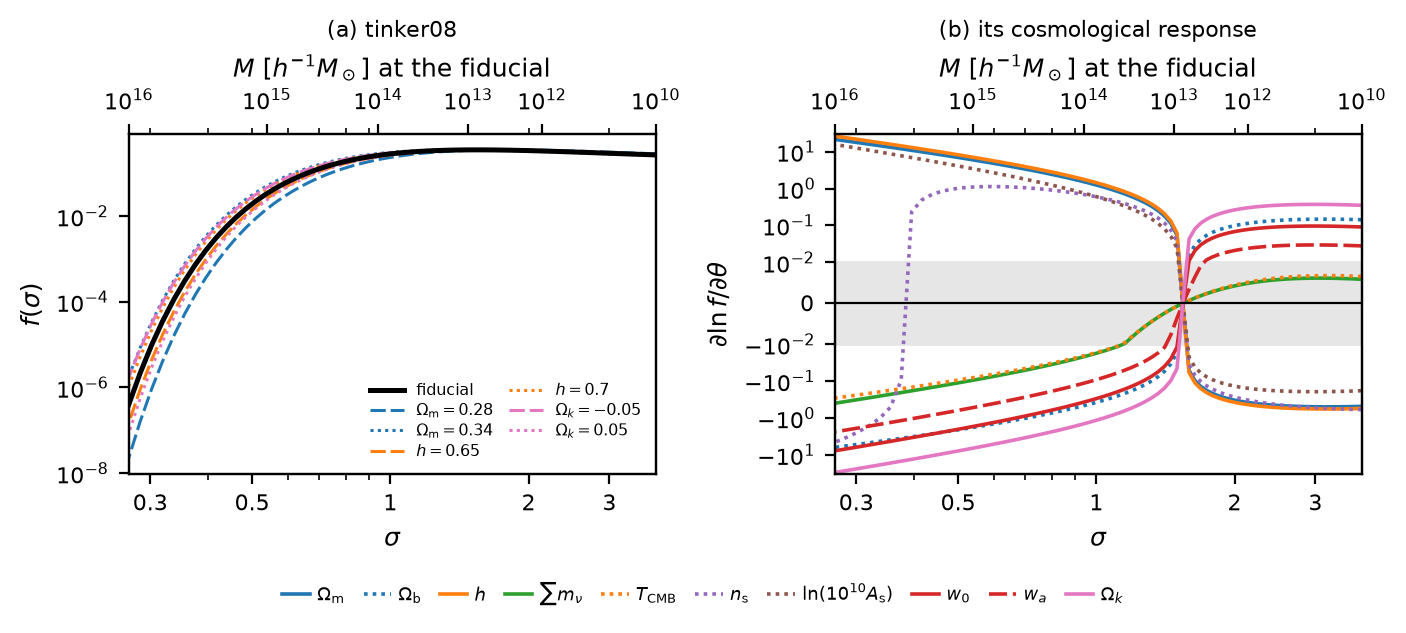

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(7.1, 3.1))
ax[0].grid(False)
ax[0].loglog(sigma, np.asarray(fit(fid.sigma, 0.0)), "k", lw=1.8, zorder=3, label="fiducial")
variant_lines(ax[0], lambda cc: np.asarray(fit(field(cc).sigma, 0.0)), sigma)
ax[0].set(xlabel=r"$\sigma$", ylabel=r"$f(\sigma)$", title="(a) tinker08", xlim=(sigma.min(), sigma.max()))
ax[0].legend(fontsize=5.6, ncol=2, loc="lower right", frameon=False, handlelength=2.2, labelspacing=0.3, columnspacing=1.0)
mass_axis_on_sigma(ax[0], sigma)
gradient_panel(ax[1], sigma, g, r"$\sigma$", r"$\partial\ln f/\partial\theta$", "(b) its cosmological response")
mass_axis_on_sigma(ax[1], sigma)
bottom_legend(fig, ax[1])
T.save_figure(fig, "fig_abundance")

## Large-scale bias

Six bias fits are provided as functions of $\nu = \delta_{\rm c}/\sigma$.
A mass function and a bias fit calibrated together are a pair; `MATCHED_BIAS` records them.
If the two are consistent, the bias-weighted mass function recovers the mean,

$$\int b(M)\,\frac{M}{\bar\rho_{\rm cb}}\frac{{\rm d}n}{{\rm d}M}\,{\rm d}M \to 1,$$

and the same integral without $b$ is the fraction of mass in haloes.
Over a finite mass range both fall short of one, so Table 4 also gives their ratio, the mean bias of the mass counted.
We recompute the table over $10^8$–$10^{16}\,h^{-1}{\rm M}_\odot$ with `emu_pk`.
The mass definition must be converted to an overdensity with respect to the mean density before it is passed to `tinker08`: $200{\rm c}$ is $\Delta\simeq 640$ mean at $z = 0$.

In [6]:
print("matched pairs:", H.MATCHED_BIAS)
mm = np.logspace(8.0, 16.0, 1024)
s_m = H.sigma_of_mass(mm, kj, pk_cb := pk.pk_cb(kj, 0.0, c), c.rho_cold)
dl_m = H.dln_sigma_dln_mass(mm, kj, pk_cb, c.rho_cold)

paper = {("press74", "press74", "200m"): (0.900, 0.764), ("tinker08", "tinker10", "200c"): (0.604, 0.508),
         ("tinker08", "tinker10", "200m"): (0.767, 0.623), ("despali16", "sheth99", "vir"): (0.669, 0.559),
         ("comparat17", "comparat17", "vir"): (0.656, 0.540), ("tinker08", "sheth01", "200c"): (0.593, 0.508)}
print(f"{'dn/dM':11s}{'b':11s}{'mdef':6s}{'int b df':>10s}{'int df':>9s}{'ratio':>8s}   paper")
for (hmf, bias, mdef), (pb, pf) in paper.items():
    delta = float(H.MassDef.from_string(mdef).delta_mean(0.0, c))
    kw = {"delta": delta} if hmf == "tinker08" else {}
    if hmf == "despali16":
        kw = {"delta_ratio": delta / float(H.MassDef("vir").delta_mean(0.0, c))}
    n_m = H.dndm(mm, s_m, dl_m, c.rho_cold, model=hmf, z=0.0, **kw)
    b_m = H.make_bias(bias)(s_m, delta)
    bdf = float(H.mass_weighted_bias(mm, n_m, b_m, c.rho_cold))
    df = float(H.mass_fraction(mm, n_m, c.rho_cold))
    print(f"{hmf:11s}{bias:11s}{mdef:6s}{bdf:10.3f}{df:9.3f}{bdf / df:8.3f}   {pb:.3f} {pf:.3f}")
    assert abs(bdf / pb - 1) < 0.02 and abs(df / pf - 1) < 0.02

matched pairs: {'press74': 'press74', 'sheth99': 'sheth99', 'tinker08': 'tinker10', 'bhattacharya11': 'bhattacharya11', 'despali16': 'sheth99', 'comparat17': 'comparat17'}


dn/dM      b          mdef    int b df   int df   ratio   paper
press74    press74    200m       0.902    0.770   1.172   0.900 0.764


tinker08   tinker10   200c       0.610    0.515   1.185   0.604 0.508
tinker08   tinker10   200m       0.770    0.629   1.224   0.767 0.623
despali16  sheth99    vir        0.672    0.564   1.191   0.669 0.559


comparat17 comparat17 vir        0.660    0.545   1.210   0.656 0.540
tinker08   sheth01    200c       0.600    0.515   1.165   0.593 0.508


Evaluating `tinker08`–`tinker10` at $200{\rm c}$ rather than $200{\rm m}$ moves the bias integral from 0.767 to 0.604, a 21 per cent effect; pairing `tinker08` with the wrong bias fit at a fixed definition moves it by 2 per cent.
Choosing the mass definition wrongly costs an order of magnitude more than choosing the partner wrongly.

## Exercises

1. Plot ${\rm d}n/{\rm d}M$ for all sixteen fits at $z = 0$ and $z = 1$, as a ratio to `tinker08`. Where do they agree best, and why there?
2. Differentiate the number of haloes above $10^{14}\,h^{-1}{\rm M}_\odot$ per $(h^{-1}{\rm Mpc})^3$ with respect to $\Omega_{\rm m}$ and $\ln(10^{10}A_{\rm s})$. Which combination do cluster counts constrain? (Notebook 09 answers it.)
3. Extend the integrals of Table 4 to $\nu = 10^{-8}$ for `press74` and for `tinker08`–`tinker10`. Which one closes, and why can the other not?

Next: notebook 06, concentrations and profiles.